# Phase 3 ? N3: ph?n t?ch ?u ti?n t? artifact offline

Dataset t08-v1.0-20261010; context r1 phase3-context-v1. Kh?ng train/inference/g?i API ho?c t?nh l?i policy. Notebook ??c output ?? x?c minh; c?c ph?p t?nh ph?n t?ch n?m trong module. Ch?y t? root ho?c notebooks, ho?c d?ng `python scripts/execute_phase3_notebook.py` (stdlib, l?u stdout v? PNG th?t).


In [1]:
from pathlib import Path
import json, platform, sys
import pandas as pd
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/analysis/plots.py').is_file(), 'Run from repo root or notebooks/'
sys.path.insert(0, str(ROOT))
from src.analysis.plots import file_info, verify_handoff
TABLES = ROOT / 'data/processed/p3_n3'
N2 = ROOT / 'data/processed/p3_n1_context_verified_20261021'
figures = json.loads((TABLES / 'figures_manifest.json').read_text(encoding='utf-8'))
impact = json.loads((TABLES / 'prediction_rank_metrics.json').read_text(encoding='utf-8'))
verify_handoff(N2)
for manifest in (figures, impact):
    for entry in manifest['outputs']:
        actual = file_info(ROOT / entry['path'])
        assert all(actual[k] == entry[k] for k in ('bytes', 'sha256')), entry['path']
assert figures['status'] == 'complete' and figures['n'] == 396 and figures['kev'] == 3
print('Python', platform.python_version(), 'dependencies', figures['dependencies'])
print('Dataset', figures['dataset_version'], 'context', figures['context']['context_version'])
print('Dates:', figures['source_dates'])
print('Inputs/versions/hashes:', [(x['path'], x['sha256']) for x in impact['inputs']])

def show_png(path):
    if '_emit_png' in globals():
        _emit_png(path)
    else:
        from IPython.display import display, Image
        display(Image(filename=str(path)))


Python 3.14.3 dependencies {'python': '3.14.3', 'matplotlib': '3.11.2', 'pandas': '3.0.6', 'numpy': '2.5.3', 'PyYAML': '6.0.3'}
Dataset t08-v1.0-20261010 context phase3-context-v2
Dates: {'epss_date': '2026-09-29', 'kev_date_released': '2026-09-30', 'kev_retrieved_date_utc': '2026-10-01'}
Inputs/versions/hashes: [('data/processed/phase1_v1_20261010/ranking_cohort.parquet', '07bdaba5b21e2f21161b1339704e68924d8f4bfa34118b8eb02ec8b51affdfff'), ('data/processed/phase1_v1_20261010/ml_cohort.parquet', 'eaa7f845596cc8b1a0ac802a792f2b495006cec87acc7cab28434fcb8905fdb6'), ('data/processed/p2_n1_reproduction_20261017/data/processed/predictions.csv', '6af4021db182ca24421f8f457e881410e272366f0dde5b30b2abacefd0fd95b1'), ('data/processed/p2_distilbert_20261017/predictions.csv', '3fa8e432a9ad84043fd323c3a088f6ec2f5624e97df050af3bc1f393d93c5f86')]


## Ranking quan s?t ? 396 CVE, 3 KEV

Ba policy d?ng c?ng cohort. Ng?y EPSS 2026-09-29; KEV released 2026-09-30, retrieved 2026-10-01 UTC. Top-50 ?? hai trang; rank ?? ???c N2 cung c?p.


policy
cvss         50
epss         50
kev_first    50
   policy  rank          cve_id  cvss_base_score    epss  is_kev   dataset_version                 cohort_id         policy_version  epss_date
     cvss     1 CVE-2014-125052              9.8 0.00643   False t08-v1.0-20261010 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1 2026-09-29
     cvss     2  CVE-2021-36392              9.8 0.00841   False t08-v1.0-20261010 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1 2026-09-29
     cvss     3  CVE-2021-36393              9.8 0.52299   False t08-v1.0-20261010 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1 2026-09-29
     cvss     4  CVE-2021-36394              9.8 0.07034   False t08-v1.0-20261010 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1 2026-09-29
     cvss     5  CVE-2023-23556              9.8 0.00891   False t08-v1.0-20261010 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1 2026-09-29
     epss     1  CVE-2023-44487              7.5 0.99999    True t08-v1.0-20261010 t08-

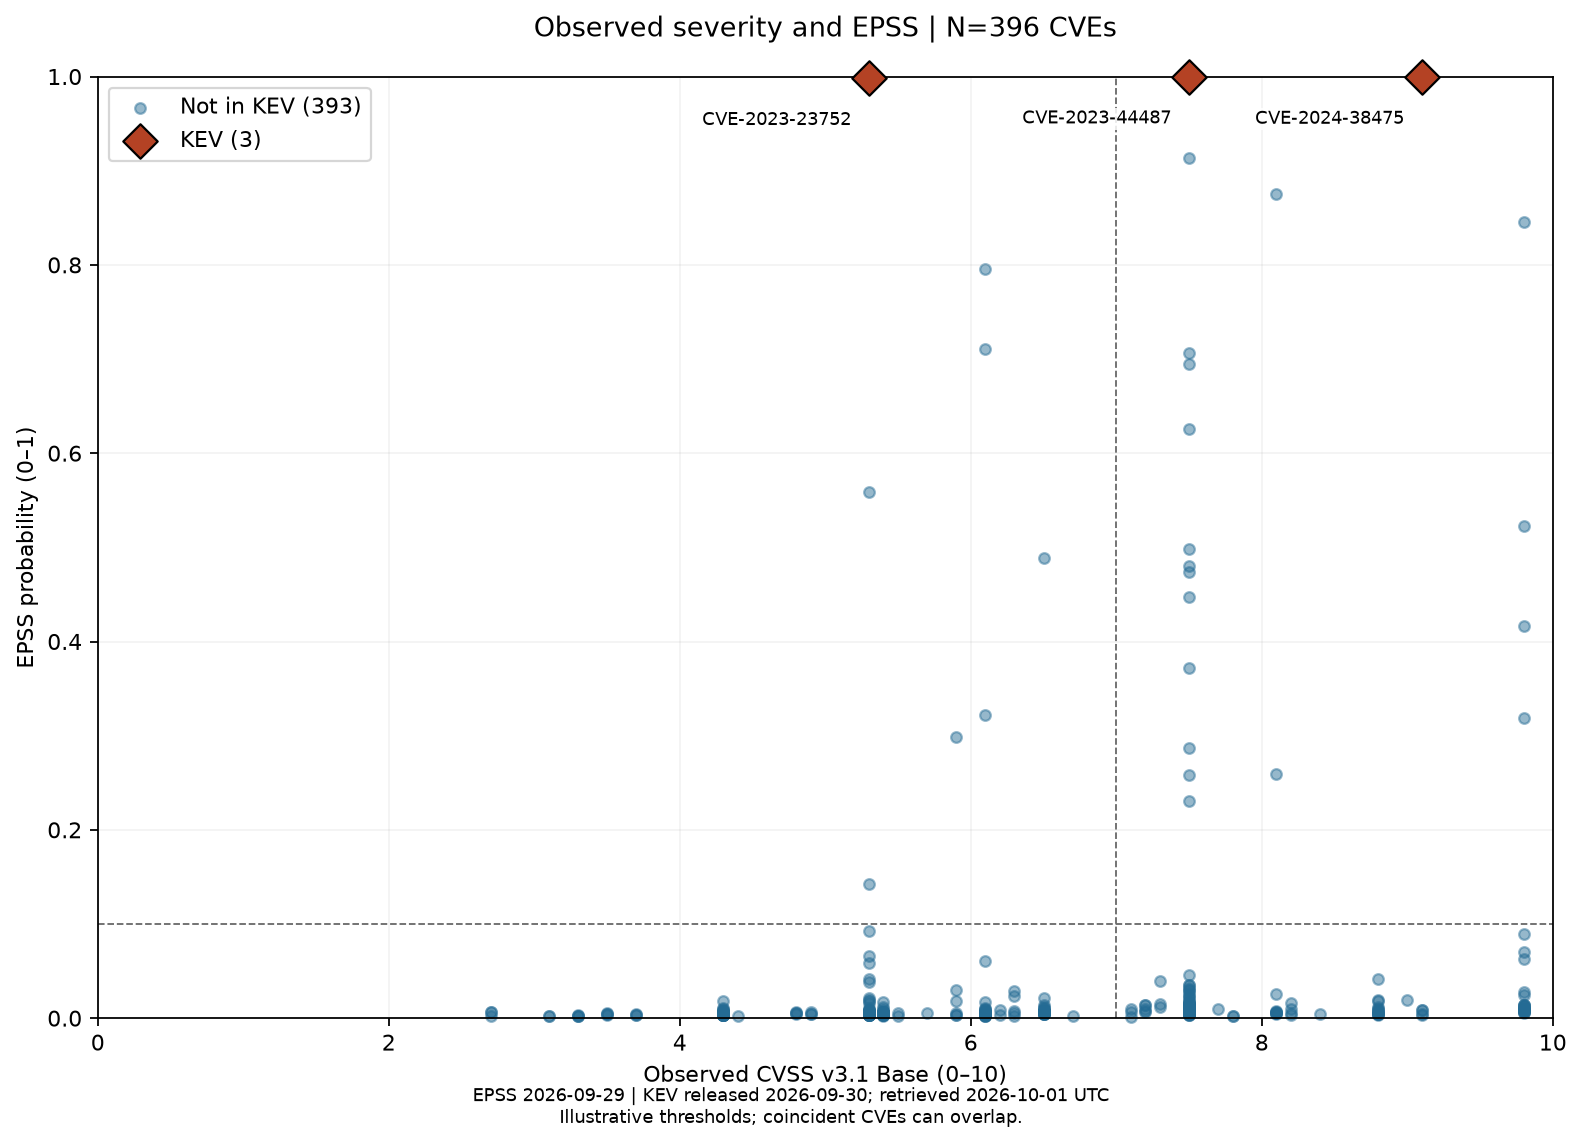

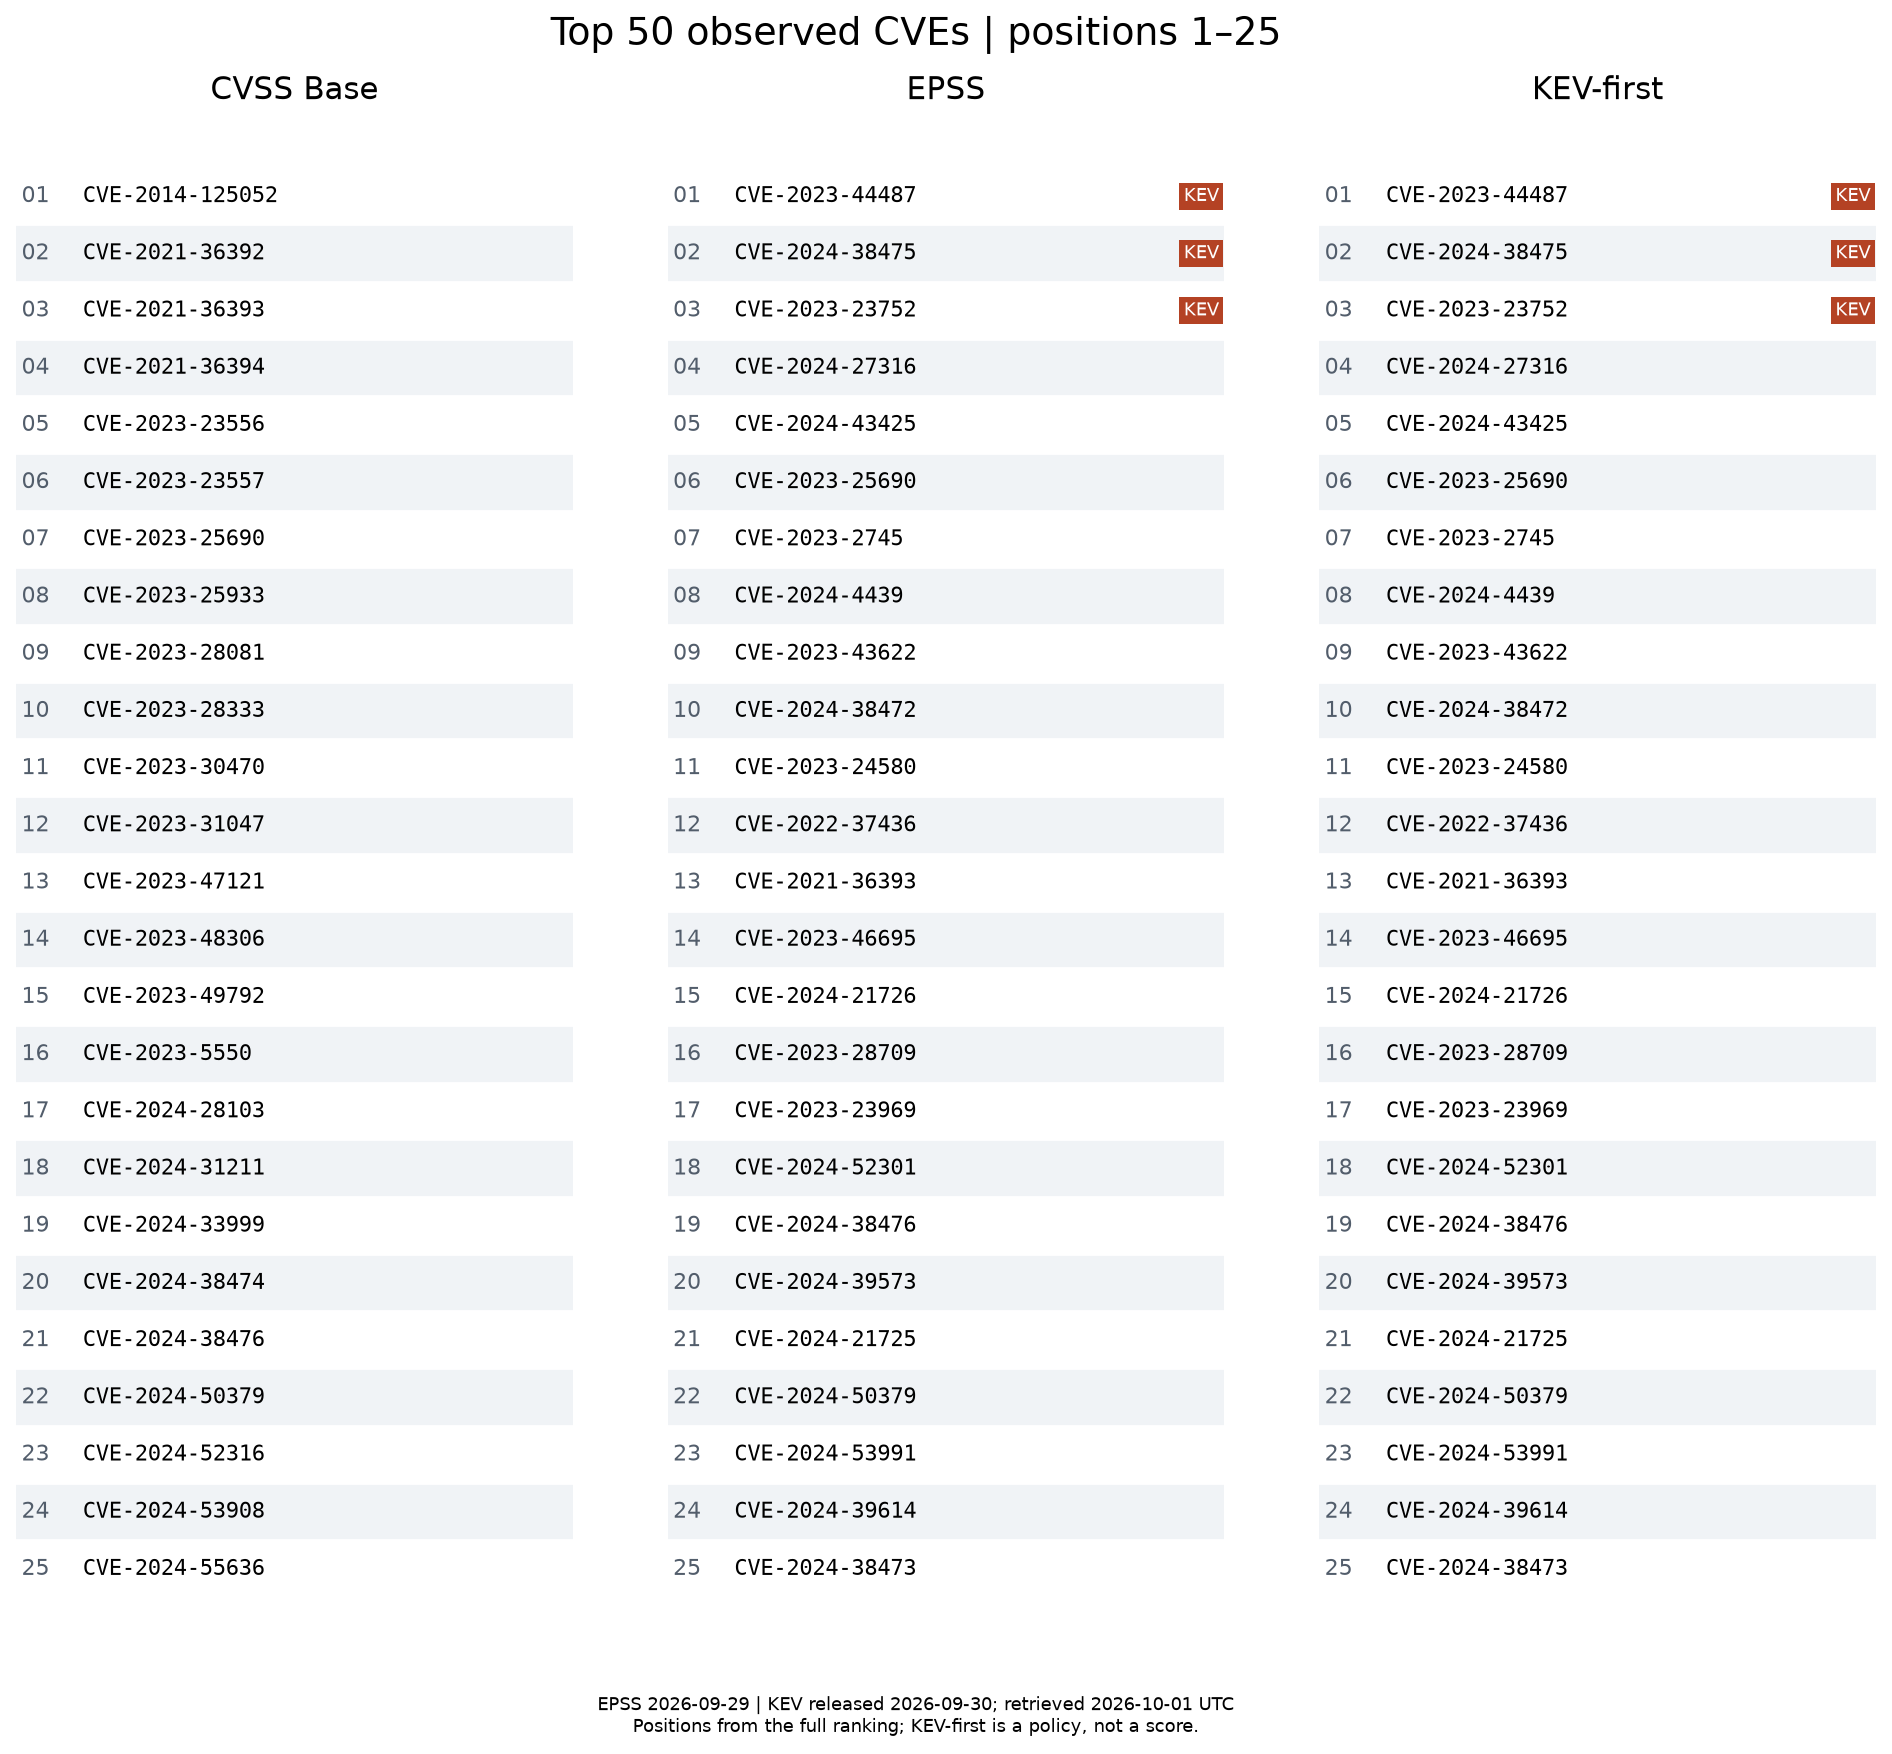

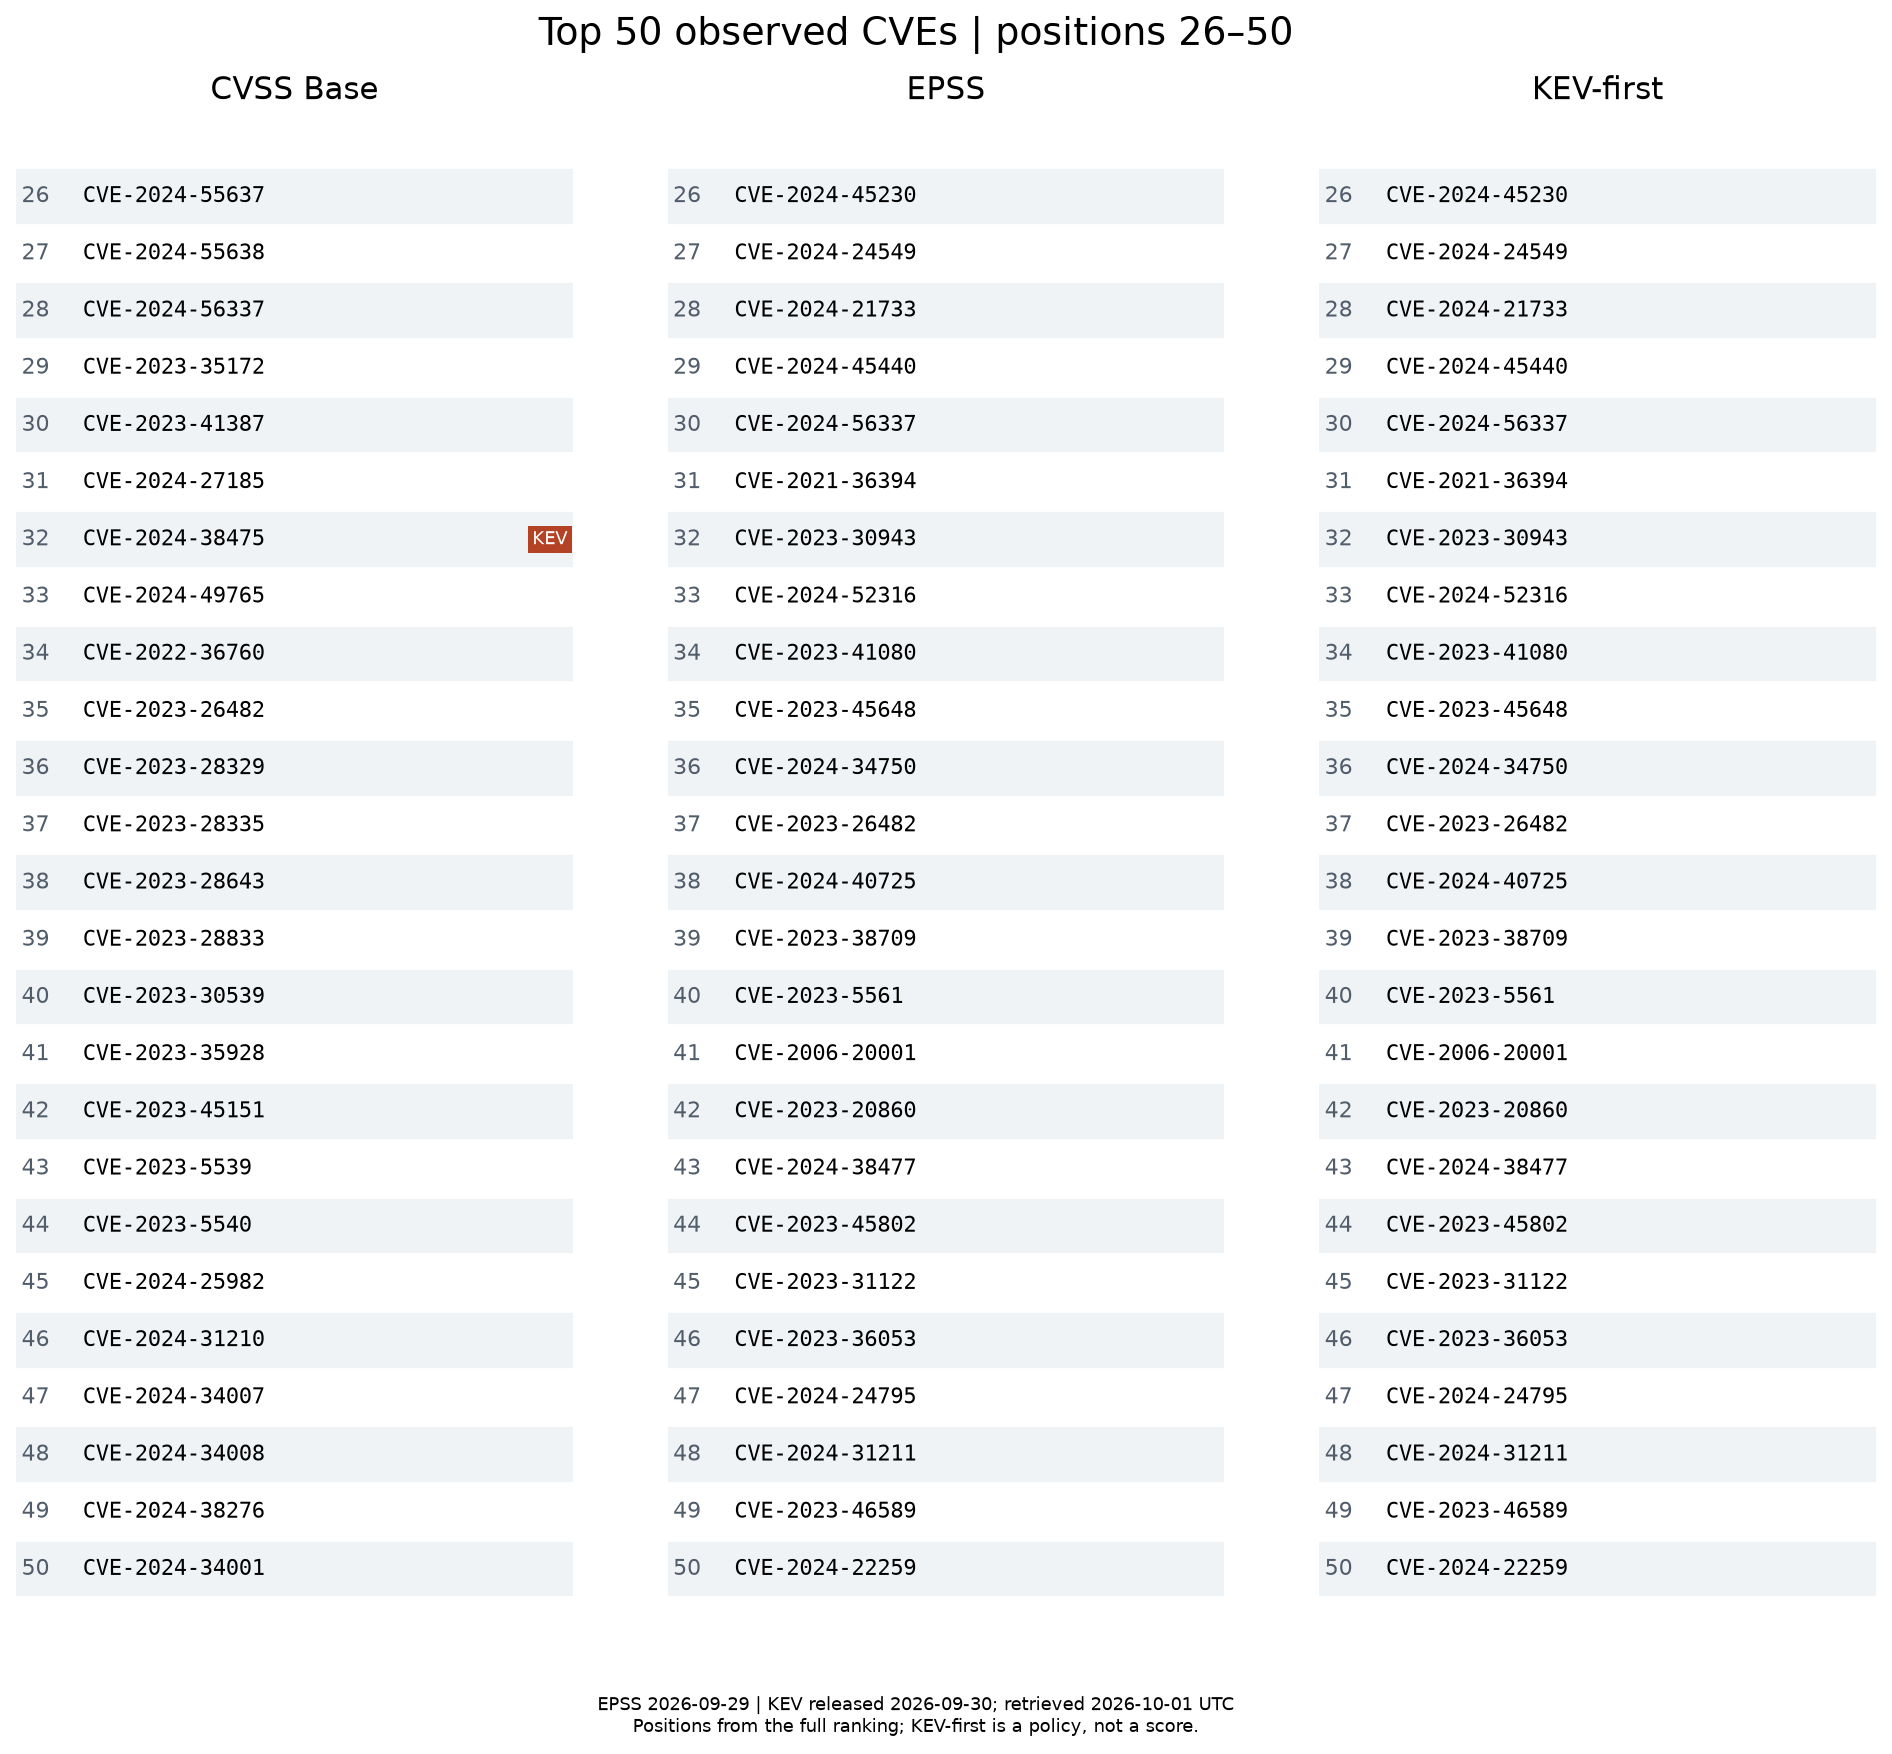

In [2]:
ranking = pd.read_csv(TABLES / 'scatter_source.csv')
top50 = pd.read_csv(TABLES / 'top50_long.csv')
print(top50.groupby('policy').size().to_string())
print(top50.groupby('policy').head(5).to_string(index=False))
for name in ('cvss_epss_scatter', 'top50_three_policies_p1', 'top50_three_policies_p2'):
    show_png(ROOT / 'reports/figures/phase3' / (name + '.png'))


## Overlap v? KEV coverage

Ch? ??c gi? tr? N2. Recall ch? CVSS/EPSS, m?u s? 3 nh?; KEV-first kh?ng l? benchmark ??c l?p. Tau-b tr?n score g?c, kh?ng t?nh t? rank ph? h?a.


policy_a  policy_b  k  intersection  union  jaccard
    cvss      epss 10             1     19 0.052632
    cvss kev_first 10             1     19 0.052632
    epss kev_first 10            10     10 1.000000
    cvss      epss 20             2     38 0.052632
    cvss kev_first 20             2     38 0.052632
    epss kev_first 20            20     20 1.000000
    cvss      epss 50            10     90 0.111111
    cvss kev_first 50            10     90 0.111111
    epss kev_first 50            50     50 1.000000
policy  k   n  kev_total  kev_hits  kev_recall  cutoff_tie_count  selected_from_cutoff_tie  selected_n  effective_k  selection_is_discriminating  selection_reason  kev_recall_reason  undefined_reason      display
  cvss 10 396          3         0    0.000000                28                        10          10           10                         True               NaN                NaN               NaN   0/3 (0.0%)
  epss 10 396          3         3    1.000000        

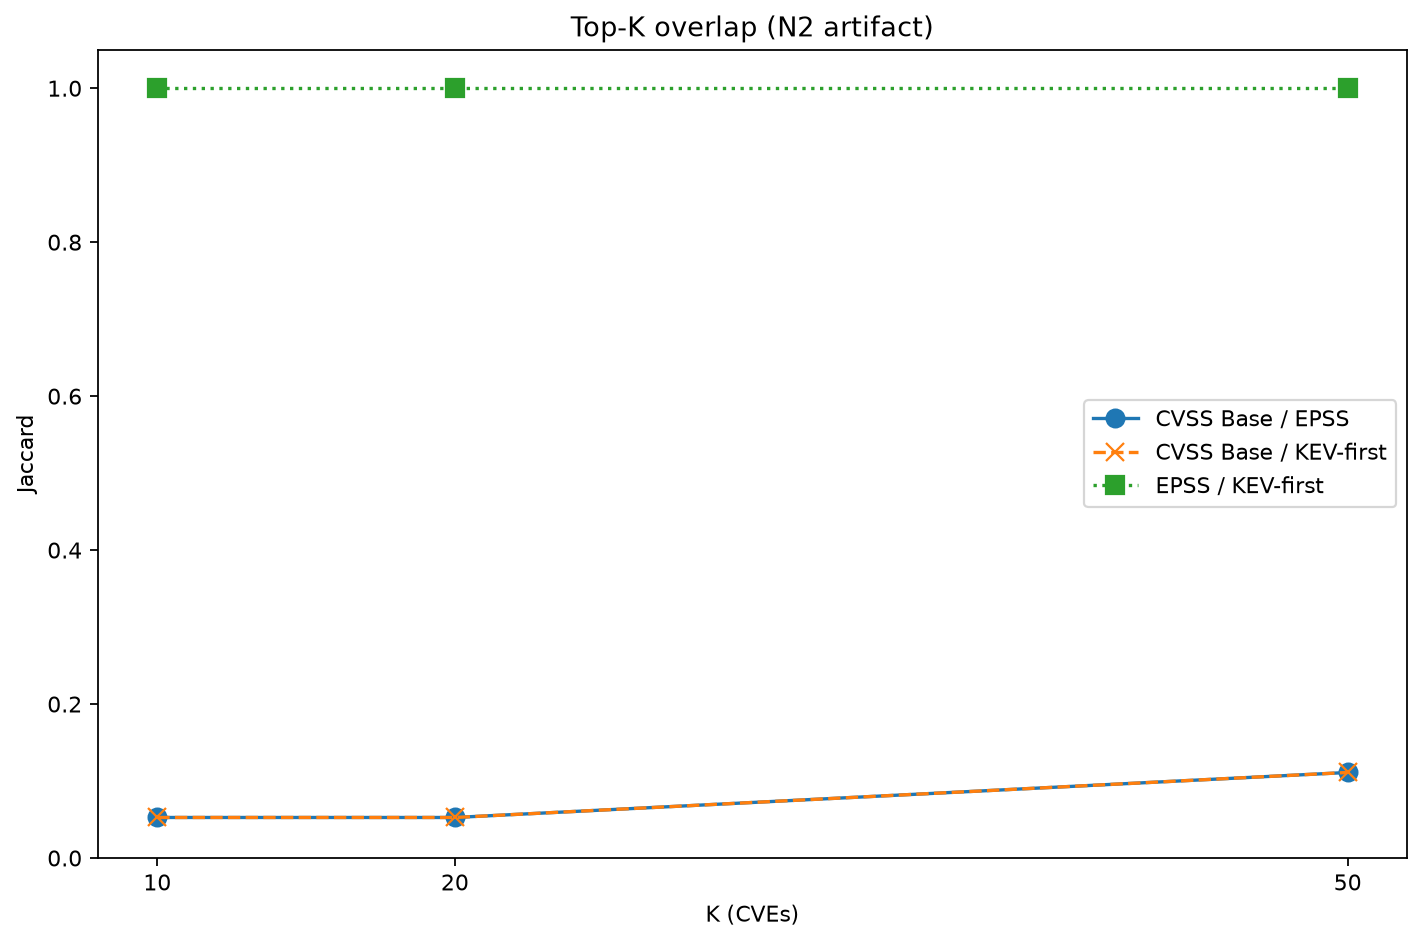

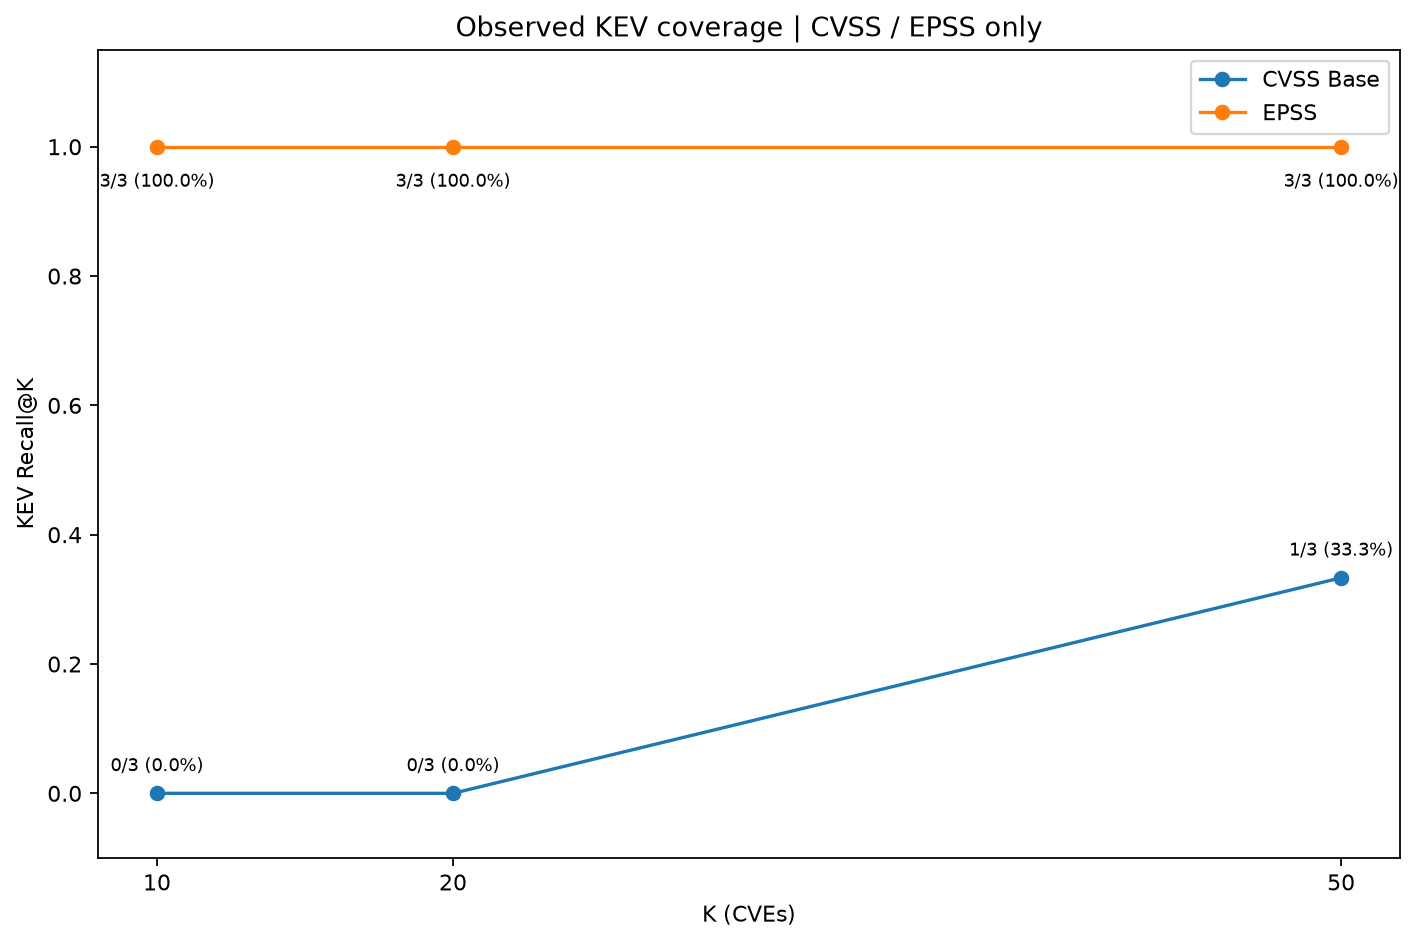

In [3]:
print(pd.read_csv(TABLES / 'overlap_plot.csv').to_string(index=False))
print(pd.read_csv(TABLES / 'kev_recall_plot.csv').to_string(index=False))
print('Raw-score tau-b:', figures['n2_ranking_metrics']['kendall_tau_b'])
for name in ('topk_overlap', 'kev_recall_at_k'):
    show_png(ROOT / 'reports/figures/phase3' / (name + '.png'))


## Context: severity kh?c v?i h?nh ??ng

C?ng 3 c?p patch tr?n hai tr?c Base/Environmental. Gi? c? 6 c?p queue, g?m 2 client review v? API-02 ch?a r? applicability. Null l? N/A, kh?ng ph?i zero.


        cve_id asset_id  base_score  environmental_score  base_rank  environmental_rank
CVE-2018-25067   WEB-01         7.2                  7.2          4                   6
CVE-2022-23548   API-01         6.5                  8.3          5                   4
CVE-2022-23549   API-01         6.5                  8.3          6                   5
CVE-2022-46177   API-01         8.1                  8.8          1                   3
CVE-2023-22453   API-01         5.3                  6.1          7                   7
CVE-2023-22626 ADMIN-01         7.5                  9.3          2                   1
CVE-2023-23620   API-01         5.3                  6.1          8                   8
CVE-2023-23621   API-01         7.5                  9.3          3                   2
   queue_status  pairs
          patch      8
review_required      7
 not_applicable      0
        cve_id asset_id  environmental_score  priority_rank                                                         

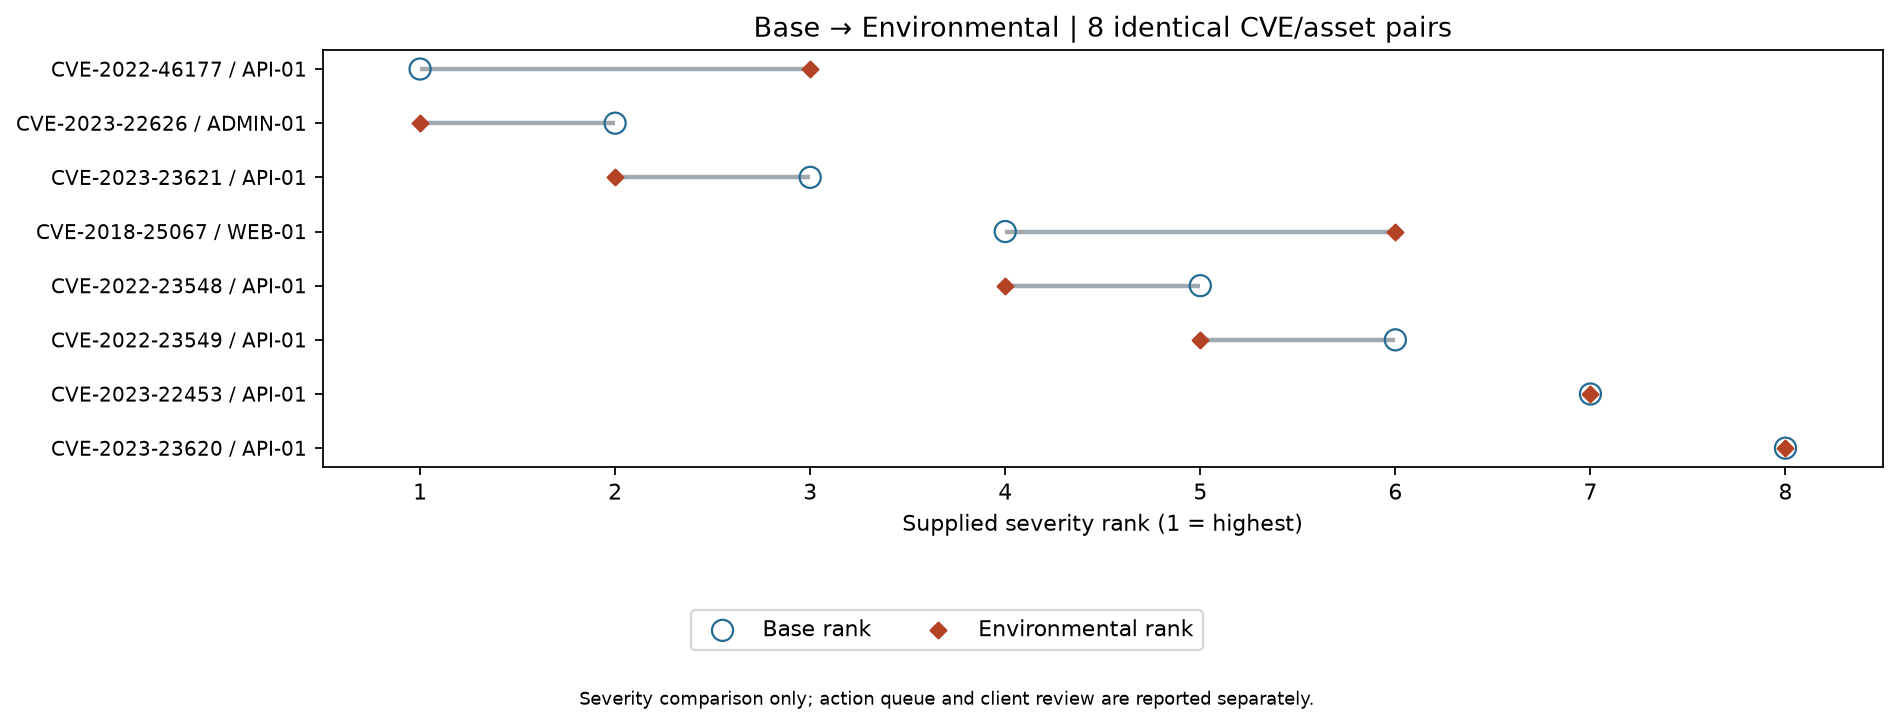

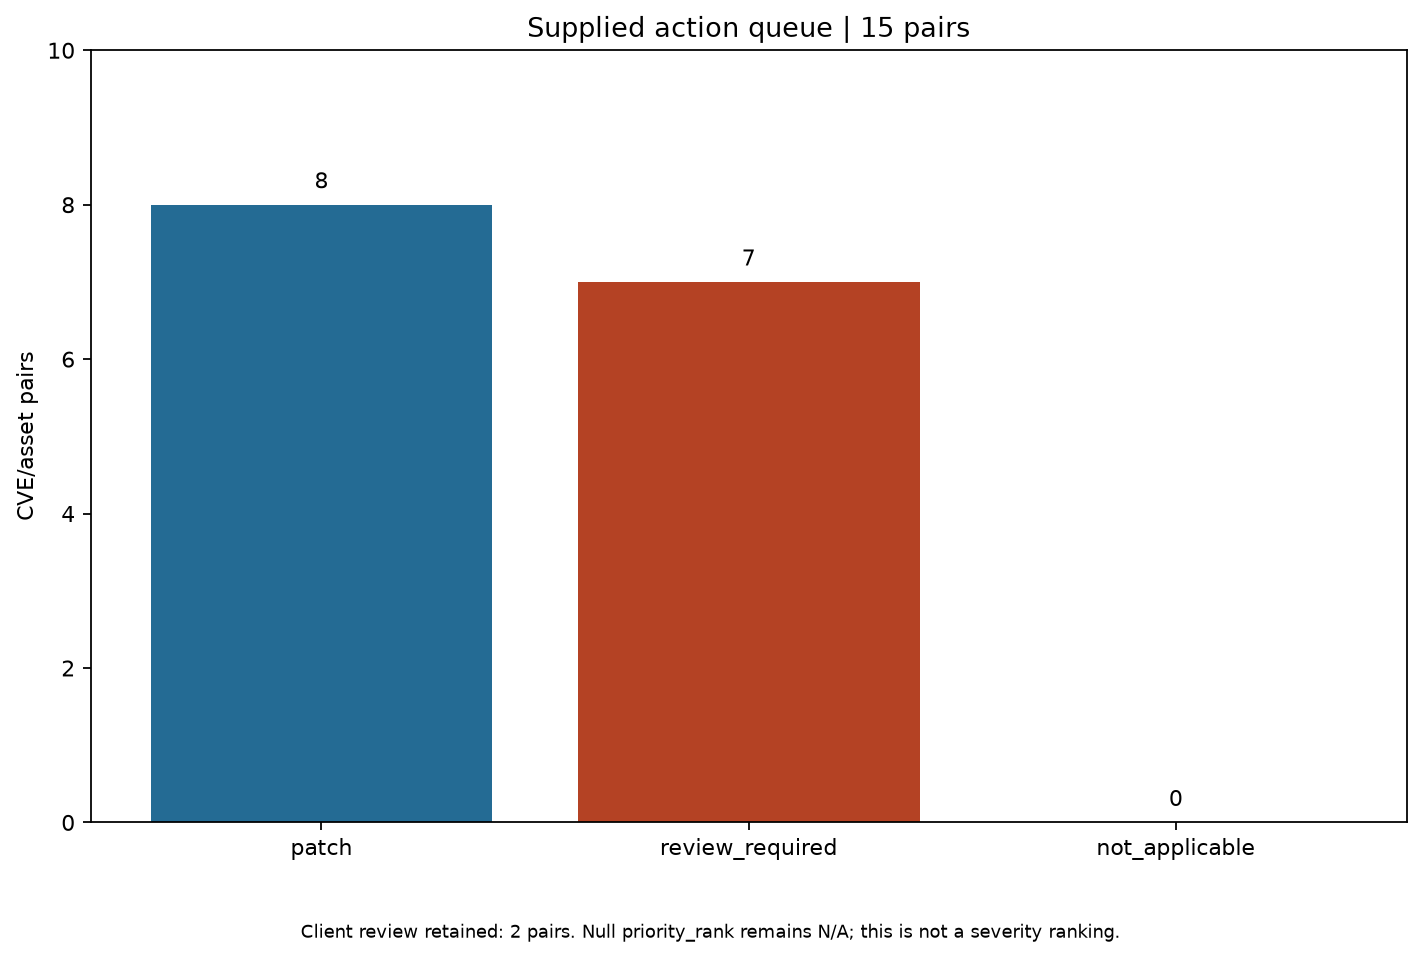

In [4]:
context = pd.read_csv(TABLES / 'context_plot.csv')
queue = pd.read_csv(TABLES / 'queue_source.csv')
print(context[['cve_id','asset_id','base_score','environmental_score','base_rank','environmental_rank']].to_string(index=False))
print(pd.read_csv(TABLES / 'queue_status_counts.csv').to_string(index=False))
print(queue.loc[queue.queue_status.eq('review_required'), ['cve_id','asset_id','environmental_score','priority_rank','priority_reason','recommended_action']].to_string(index=False, na_rep='N/A'))
for name in ('context_rank_changes', 'priority_queue_status'):
    show_png(ROOT / 'reports/figures/phase3' / (name + '.png'))


## Sai s? AI ? ch? held-out, t?ch split

Base gi?m ? CVE ID t?ng; delta observed?predicted, d??ng l? prediction x?p s?m h?n. C?ng IDs cho observed/TF-IDF/DistilBERT, K10/20/50 khi K<N. Kh?ng th?m train ho?c ch?n model theo test.


In [5]:
comparison = pd.read_csv(TABLES / 'predicted_rank_comparison.csv')
print('Join audit:', impact['join_audit'])
summary=[]
for split in impact['splits']:
    for model in split['models']:
        coverage=split['coverage'][model['model']]
        summary.append({'split':split['split'], 'model':model['model'], 'N':model['n'],
                        'missing':coverage['missing'], 'invalid':coverage['invalid'],
                        'common_coverage':coverage['common_coverage'], 'tau_b':model['kendall_tau_b'],
                        **{'J@'+str(j['k']):j['value'] for j in model['jaccard']}})
print(pd.DataFrame(summary).to_string(index=False))
print(comparison.groupby(['split','model']).head(2).to_string(index=False))


Join audit: {'ranking_ids': 396, 'ml_ids': 67242, 'ranking_missing_from_ml': 0, 'ranking_missing_from_ml_ids': [], 'train_excluded': 219, 'heldout_ids': 177}
     split      model   N  missing  invalid  common_coverage    tau_b     J@10     J@20     J@50
validation      tfidf  69        0        0              1.0 0.237847 0.111111 0.333333 0.639344
validation distilbert  69        0        0              1.0 0.243516 0.111111 0.428571 0.666667
      test      tfidf 108        0        0              1.0 0.211954 0.333333 0.333333 0.333333
      test distilbert 108        0        0              1.0 0.243259 0.333333 0.481481 0.449275
        cve_id  cvss_base_score  predicted_base_score      split      model                     model_version   dataset_version                           policy_version   n  eligible  common_coverage  observed_rank  predicted_rank  rank_delta
CVE-2023-38709              7.3                   9.1 validation      tfidf tfidf-v1-n1-reproduction-20261017 t08-

## Case mobile v? ??i chi?u ??c l?p

[CVE-2023-41387 / MOB-02](../docs/cases/p3-mobile-n3.md) thu?c train, kh?ng ph?i l?i held-out. [Crosscheck](../reports/p3_environmental_crosscheck_n3.md) thay s? theo FIRST, kh?ng g?i scorer N2.


In [6]:
mobile = ranking.loc[ranking.cve_id.eq('CVE-2023-41387')]
print(mobile.to_string(index=False))
crosscheck=json.loads((TABLES / 'environmental_crosscheck_n3.json').read_text(encoding='utf-8'))
assert crosscheck['status']=='pass'
print(json.dumps(crosscheck, ensure_ascii=False, indent=2))
print('UI contract: docs/phase-4-ui-contract.md')
print('N1 integrated context-v2; see docs/phase-3-completion.md.')


        cve_id  cvss_base_score    epss  is_kev  cvss_rank  epss_rank  kev_first_rank   dataset_version  epss_date                 cohort_id         policy_version
CVE-2023-41387              9.1 0.00874   False         30        128             127 t08-v1.0-20261010 2026-09-29 t08-v1.0-20261010:ranking cvss-epss-kev-first-v1
{
  "status": "pass",
  "cve_id": "CVE-2023-41387",
  "asset_id": "MOB-02",
  "base_vector": "CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:N/I:H/A:H",
  "environmental_vector": "CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:N/I:H/A:H/E:X/RL:X/RC:X/CR:H/IR:H/AR:M/MAV:X/MAC:X/MPR:X/MUI:X/MS:X/MC:X/MI:X/MA:X",
  "calculation": {
    "raw_miss": "0.929600",
    "miss": "0.915",
    "modified_impact": "5.87430",
    "modified_exploitability": "3.8870427750",
    "sum": "9.7613427750",
    "inner_roundup": "9.8",
    "expected": 9.8
  },
  "n2_score": 9.8,
  "difference": 0.0,
  "source": "https://www.first.org/cvss/v3.1/specification-document#7-3-Environmental-Metrics-Equations",
  "datase